In [ ]:
# ==============================
# Cell 1: Setup & Config
# ==============================
import os, gc, math, json, random, pathlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import make_scorer
from IPython.display import display

warnings.filterwarnings("ignore")

# Paths (Sesuaikan jika perlu)
try:
    DATA_DIR = Path("/kaggle/input/intelecta-cup-data-mining-competition")
    if not DATA_DIR.exists(): DATA_DIR = Path(".")
except: DATA_DIR = Path(".")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH  = DATA_DIR / "test.csv"
SUB_PATH   = DATA_DIR / "sample_submission.csv"

# Parameters
TARGET = "Suhu_Rata_Rata_C"
ID_COL = "ID"
SEED   = 42
EPS    = 0.5 # epsilon untuk stabilized MAPE (evaluasi)
EPS_WEIGHT = 1.0  # Konstanta minimum untuk denominator sample weight (PENTING!)

def set_seed(seed=SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

set_seed(SEED)
print("Configured. Using data from:", DATA_DIR.resolve())

SMALL_VALUE_THRESHOLD = 1.0

Configured. Using data from: /kaggle/input/intelecta-cup-data-mining-competition


In [2]:
# ==============================
# Cell 2: Load Data
# ==============================
try:
    train = pd.read_csv(TRAIN_PATH)
    test  = pd.read_csv(TEST_PATH)
    sub   = pd.read_csv(SUB_PATH)
except FileNotFoundError:
    print("Error: Data files not found. Check DATA_DIR path.")
    raise

train['is_train'] = 1
test['is_train'] = 0
all_df = pd.concat([train, test], ignore_index=True)
all_df = all_df.sort_values(by=ID_COL).reset_index(drop=True)

print("train:", train.shape, "| test:", test.shape, "| all_df:", all_df.shape)

train: (8000, 16) | test: (2000, 15) | all_df: (10000, 16)


Target zero count: 0
Target negative count: 971


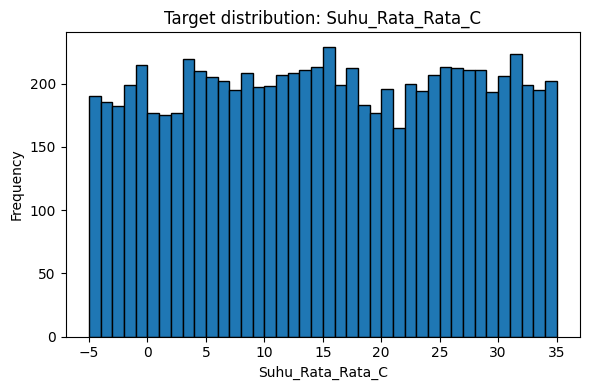

In [3]:
# ==============================
# Cell 3: Quick Target & Columns Check
# ==============================
assert TARGET in train.columns, f"Target '{TARGET}' not found in train."
print("Target zero count:", (train[TARGET]==0).sum())
print("Target negative count:", (train[TARGET]<0).sum())

plt.figure(figsize=(6,4))
train[TARGET].plot(kind="hist", bins=40, edgecolor="black")
plt.title(f"Target distribution: {TARGET}")
plt.xlabel(TARGET); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()

In [4]:
# ==============================
# Cell 4: Utility - MAPE with epsilon (untuk EVALUASI)
# ==============================
def mape_eps(y_true, y_pred, eps=EPS):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.maximum(np.abs(y_true), eps)
    return np.mean(np.abs(y_true - y_pred) / denom) * 100.0

print("Test mape_eps:", mape_eps([1,2,3],[1,2,4]))

Test mape_eps: 11.11111111111111


In [5]:
# ==============================
# Cell 5: Basic Dtypes & Column Lists
# ==============================
cat_cols = all_df.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in all_df.columns if c not in [TARGET, ID_COL, 'is_train'] and c not in cat_cols]

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

Categorical columns: ['Nama_Negara', 'Wilayah', 'Jenis_Tanaman', 'Strategi_Adaptasi']
Numeric columns: ['Tahun', 'Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Hasil_Panen_Ton_per_HA', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']


In [6]:
# ==============================
# Cell 6: Imputation (median per Wilayah)
# ==============================
GROUP_COL = "Wilayah"
print(f"Starting imputation based on group: {GROUP_COL}")

for c in cat_cols:
    all_df[c] = all_df[c].fillna("UNK")

num_cols_impute = [c for c in num_cols if c != 'Tahun']

df_train_only = all_df[all_df['is_train'] == 1]
med_map = df_train_only.groupby(GROUP_COL)[num_cols_impute].median()
global_medians = df_train_only[num_cols_impute].median()

for c in num_cols_impute:
    all_df[c] = all_df[c].fillna(all_df[GROUP_COL].map(med_map[c]))
    all_df[c] = all_df[c].fillna(global_medians[c])

print("Imputation done. NaN counts in all_df:", all_df.isna().sum().sum())

Starting imputation based on group: Wilayah
Imputation done. NaN counts in all_df: 2000


In [7]:
# ==============================
# Cell 7: Winsorize per group
# ==============================
def winsorize_per_group(df, cols, group_col=None, p_low=0.02, p_high=0.98):
    df_out = df.copy()
    if not cols: return df_out

    print(f"Winsorizing based on group: {group_col}")
    df_train_only = df[df['is_train']==1]

    for c in cols:
        s_lo = df_train_only.groupby(group_col)[c].quantile(p_low)
        s_hi = df_train_only.groupby(group_col)[c].quantile(p_high)
        glo = df_train_only[c].quantile(p_low)
        ghi = df_train_only[c].quantile(p_high)

        lo = df_out[group_col].map(s_lo).fillna(glo)
        hi = df_out[group_col].map(s_hi).fillna(ghi)

        df_out[c] = np.clip(df_out[c].values, lo.values, hi.values)
    return df_out

num_cols_winsorize = [c for c in num_cols if c != 'Tahun']
all_df = winsorize_per_group(all_df, num_cols_winsorize, GROUP_COL, 0.02, 0.98)

print("Winsorizing done.")

Winsorizing based on group: Wilayah
Winsorizing done.


In [8]:
# ==============================
# Cell A1: Transform & cap hasil panen
# ==============================
PANEN = "Hasil_Panen_Ton_per_HA"
if PANEN in all_df.columns:
    print(f"Transforming '{PANEN}'...")

    df_train_only = all_df[all_df['is_train']==1]
    q1 = df_train_only.groupby(GROUP_COL)[PANEN].quantile(0.01)
    q9 = df_train_only.groupby(GROUP_COL)[PANEN].quantile(0.99)
    glo1 = df_train_only[PANEN].quantile(0.01)
    ghi9 = df_train_only[PANEN].quantile(0.99)

    lo = all_df[GROUP_COL].map(q1).fillna(glo1)
    hi = all_df[GROUP_COL].map(q9).fillna(ghi9)
    all_df[PANEN] = np.clip(all_df[PANEN].values, lo.values, hi.values)

    shift = max(1e-6, float((df_train_only[PANEN].min() <= 0)) * (abs(df_train_only[PANEN].min()) + 1e-3))
    all_df[PANEN+"_log"] = np.log1p(all_df[PANEN] + shift)

    if PANEN in num_cols: num_cols.remove(PANEN)
    if PANEN+"_log" not in num_cols: num_cols.append(PANEN+"_log")
    all_df.drop(columns=[PANEN], errors="ignore", inplace=True)

    print("Panen transformed (log) and capped.")
else:
    print(f"Column '{PANEN}' not found.")

Transforming 'Hasil_Panen_Ton_per_HA'...
Panen transformed (log) and capped.


In [9]:
# ==============================
# Cell 8: Advanced Feature Engineering (RASIO, LAGS, PEMBERSIHAN)
# ==============================
print("Membuat Fitur Rasio, Lag, dan Geo...")
panen_col = PANEN+"_log" if PANEN+"_log" in all_df.columns else PANEN

# --- 1. Fitur Rasio & Interaksi ---
safe_div = lambda a, b: a / (b + 1e-6)
all_df["Curah_per_CO2"] = safe_div(all_df["Total_Curah_Hujan_mm"], all_df["Emisi_CO2_JT_Ton"])
all_df["Pupuk_per_Pestisida"] = safe_div(all_df["Penggunaan_Pupuk_KG_per_HA"], all_df["Penggunaan_Pestisida_KG_per_HA"])
if panen_col in all_df.columns:
    all_df["Hasil_per_Curah"] = safe_div(all_df[panen_col], all_df["Total_Curah_Hujan_mm"])
else: print(f"Warning: Column '{panen_col}' not found for 'Hasil_per_Curah'.")
all_df["Irigasi_x_Hujan"] = all_df["Akses_Irigasi"] * all_df["Total_Curah_Hujan_mm"]

# --- 2. Fitur Geo-Temporal ---
zona_map = {'Russia': 3, 'Canada': 3, 'USA': 2, 'China': 2, 'France': 2, 'India': 1, 'Nigeria': -1, 'Brazil': -1, 'Argentina': -2, 'Australia': -2}
all_df['Zona_Iklim'] = all_df['Nama_Negara'].map(zona_map).fillna(0)
all_df["Tahun_sq"] = (all_df["Tahun"] - 1990)**2

# --- 3. Interaksi Kategori ---
all_df['Negara_Wilayah'] = all_df['Nama_Negara'].astype(str) + '_' + all_df['Wilayah'].astype(str)
if 'Negara_Wilayah' not in cat_cols:
    cat_cols.append('Negara_Wilayah')

# --- 4. Lag Features (Time Series) ---
all_df = all_df.sort_values(by=['Wilayah', 'Tahun'])
lag_cols = ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', panen_col, 'Penggunaan_Pupuk_KG_per_HA']
created_lag_cols = []
for col in lag_cols:
    if col in all_df.columns:
        lag_col_name = f'Lag_1_{col}'
        all_df[lag_col_name] = all_df.groupby('Wilayah')[col].shift(1)
        med_lag = all_df[all_df['is_train']==1].groupby('Wilayah')[lag_col_name].median()
        all_df[lag_col_name] = all_df[lag_col_name].fillna(all_df['Wilayah'].map(med_lag))
        all_df[lag_col_name] = all_df[lag_col_name].fillna(0)
        created_lag_cols.append(lag_col_name)
    else: print(f"Warning: Column '{col}' not found for lag feature creation.")

all_df = all_df.sort_index()

# --- 5. (KRUSIAL) Pembersihan Fitur Baru ---
print("Membersihkan inf dan NaN dari fitur baru...")
new_num_cols = [
    'Curah_per_CO2', 'Pupuk_per_Pestisida', 'Hasil_per_Curah', 'Irigasi_x_Hujan',
    'Tahun_sq', 'Zona_Iklim'
] + created_lag_cols

for col in new_num_cols:
    if col in all_df.columns:
        all_df[col] = all_df[col].replace([np.inf, -np.inf], np.nan)
        all_df[col] = all_df[col].fillna(0)

print("Feature engineering (Rasio, Lag) complete.")

Membuat Fitur Rasio, Lag, dan Geo...
Membersihkan inf dan NaN dari fitur baru...
Feature engineering (Rasio, Lag) complete.


In [ ]:
# ==============================
# Cell 8b: Aggregate Features
# ==============================
print("Membuat Fitur Agregat...")

agg_group_cols = ['Wilayah', 'Nama_Negara', 'Jenis_Tanaman', 'Strategi_Adaptasi']
agg_num_cols = ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah']

df_train_only = all_df[all_df['is_train']==1].copy()
added_agg_features = []

for group_col in agg_group_cols:
    for num_col in agg_num_cols:
        if group_col in df_train_only.columns and num_col in df_train_only.columns:
            print(f"  Menghitung agregat untuk {group_col} / {num_col}...")
            mean_col = f'Agg_{group_col}_{num_col}_mean'
            std_col = f'Agg_{group_col}_{num_col}_std'
            stats = df_train_only.groupby(group_col)[num_col].agg(['mean', 'std']).reset_index()
            stats.columns = [group_col, mean_col, std_col]
            all_df = pd.merge(all_df, stats, on=group_col, how='left')
            added_agg_features.extend([mean_col, std_col])
        else: print(f"Warning: Columns '{group_col}' or '{num_col}' not found.")

all_df[added_agg_features] = all_df[added_agg_features].fillna(0)

print(f"Fitur Agregat selesai. Menambahkan {len(added_agg_features)} fitur baru.")

Membuat Fitur Agregat...
  Menghitung agregat untuk Wilayah / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Wilayah / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Wilayah / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Wilayah / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Nama_Negara / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Nama_Negara / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Nama_Negara / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Nama_Negara / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Jenis_Tanaman / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Jenis_Tanaman / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Jenis_Tanaman / Penggunaan_Pupuk_KG_per_HA...
  Menghitung agregat untuk Jenis_Tanaman / Indeks_Kesehatan_Tanah...
  Menghitung agregat untuk Strategi_Adaptasi / Total_Curah_Hujan_mm...
  Menghitung agregat untuk Strategi_Adaptasi / Emisi_CO2_JT_Ton...
  Menghitung agregat untuk Strategi_Adaptasi / Penggu

In [11]:
# ==============================
# Cell 9: Prepare features (Dengan PowerTransformer + FEATURE SELECTION)
# ==============================
# Pisahkan kembali train dan test
train = all_df[all_df['is_train']==1].drop(columns=['is_train'])
test = all_df[all_df['is_train']==0].drop(columns=['is_train', TARGET])

# Ambil SEMUA kolom potensial dulu
ALL_POTENTIAL_FEATURES = [c for c in train.columns if c not in [TARGET, ID_COL]]

# --- FEATURE SELECTION: Hapus turunan Hasil Panen ---
panen_col_log = PANEN + "_log" if PANEN + "_log" in ALL_POTENTIAL_FEATURES else None

features_to_drop = []
if panen_col_log:
    print(f"Mengidentifikasi fitur turunan dari '{panen_col_log}' untuk dihapus...")
    for feature in ALL_POTENTIAL_FEATURES:
        if feature == panen_col_log: continue
        if panen_col_log in feature or "Hasil_per_Curah" in feature:
             if feature.startswith("Agg_") and panen_col_log in feature: features_to_drop.append(feature)
             elif feature.startswith("Lag_") and panen_col_log in feature: features_to_drop.append(feature)
             elif "Hasil_per_Curah" in feature: features_to_drop.append(feature)

    print(f"Fitur turunan hasil panen yang akan dihapus ({len(features_to_drop)}): {features_to_drop}")
else:
    print("Kolom hasil panen (log) tidak ditemukan, tidak ada fitur turunan yang dihapus.")

FEATURES = [f for f in ALL_POTENTIAL_FEATURES if f not in features_to_drop]
print(f"Jumlah fitur setelah seleksi: {len(FEATURES)}\n")

X = train[FEATURES].copy()
y = train[TARGET].values
X_test = test[FEATURES].copy()

y = pd.Series(y, index=X.index).fillna(0).values
print(f"Membersihkan y (asli). Jumlah NaN di y: {np.isnan(y).sum()}")

# --- POWER TRANSFORMER (Yeo-Johnson) ---
numeric_features_all = X.select_dtypes(include=np.number).columns.tolist()
if 'Tahun' in numeric_features_all: numeric_features_all.remove('Tahun')

numeric_features_existing = [col for col in numeric_features_all if col in X.columns]
print(f"\nKolom numerik yang akan di-transform Power ({len(numeric_features_existing)}): {numeric_features_existing}")

pt = PowerTransformer(method='yeo-johnson', standardize=True)
X[numeric_features_existing] = pt.fit_transform(X[numeric_features_existing])
X_test[numeric_features_existing] = pt.transform(X_test[numeric_features_existing])
print("Fitur numerik telah di-transformasi.")

cat_cols_final = X.select_dtypes(include=["object", "category"]).columns.tolist()
for c in cat_cols_final:
    X[c] = X[c].astype(str)
    X_test[c] = X_test[c].astype(str)

print("\nn_features:", len(FEATURES))
print("Final Categorical columns:", cat_cols_final)
print("X shape:", X.shape, "| X_test shape:", X_test.shape)

Mengidentifikasi fitur turunan dari 'Hasil_Panen_Ton_per_HA_log' untuk dihapus...
Fitur turunan hasil panen yang akan dihapus (2): ['Hasil_per_Curah', 'Lag_1_Hasil_Panen_Ton_per_HA_log']
Jumlah fitur setelah seleksi: 54

Membersihkan y (asli). Jumlah NaN di y: 0

Kolom numerik yang akan di-transform Power (48): ['Total_Curah_Hujan_mm', 'Emisi_CO2_JT_Ton', 'Kejadian_Cuaca_Ekstrim', 'Akses_Irigasi', 'Penggunaan_Pestisida_KG_per_HA', 'Penggunaan_Pupuk_KG_per_HA', 'Indeks_Kesehatan_Tanah', 'Hasil_Panen_Ton_per_HA_log', 'Curah_per_CO2', 'Pupuk_per_Pestisida', 'Irigasi_x_Hujan', 'Zona_Iklim', 'Tahun_sq', 'Lag_1_Total_Curah_Hujan_mm', 'Lag_1_Emisi_CO2_JT_Ton', 'Lag_1_Penggunaan_Pupuk_KG_per_HA', 'Agg_Wilayah_Total_Curah_Hujan_mm_mean', 'Agg_Wilayah_Total_Curah_Hujan_mm_std', 'Agg_Wilayah_Emisi_CO2_JT_Ton_mean', 'Agg_Wilayah_Emisi_CO2_JT_Ton_std', 'Agg_Wilayah_Penggunaan_Pupuk_KG_per_HA_mean', 'Agg_Wilayah_Penggunaan_Pupuk_KG_per_HA_std', 'Agg_Wilayah_Indeks_Kesehatan_Tanah_mean', 'Agg_Wilayah

In [ ]:
# ==============================
# Cell 9b: Target Transformation
# ==============================
def signed_log1p(y):
    return np.sign(y) * np.log1p(np.abs(y))

def inverse_signed_log1p(y_transformed):
    return np.sign(y_transformed) * (np.expm1(np.abs(y_transformed)))

y_transformed = signed_log1p(y)
print("Target telah di-transformasi menggunakan signed_log1p.")

Target telah di-transformasi menggunakan signed_log1p.


In [13]:
# ==============================
# Cell B1: Sample weight
# ==============================
w = 1.0 / np.maximum(np.abs(y), EPS_WEIGHT)
w = pd.Series(w).fillna(1.0).values
print(f"Membersihkan w. Jumlah NaN di w: {np.isnan(w).sum()}")
print("Sample weight stats:", float(np.min(w)), float(np.median(w)), float(np.max(w)))

Membersihkan w. Jumlah NaN di w: 0
Sample weight stats: 0.02857142857142857 0.06605019815059444 1.0


In [14]:
# ==============================
# Cell 10: CV Split (GroupKFold by Tahun)
# ==============================
groups = train["Tahun"].values
n_splits = 5
gkf = GroupKFold(n_splits=n_splits)
print(f"Use GroupKFold by Tahun dengan {n_splits} splits.")

Use GroupKFold by Tahun dengan 5 splits.


In [ ]:
# ==============================
# Cell 11: Latih Model Utama (CatBoost)
# ==============================
print("\n--- Melatih Model Utama: CatBoost ---")
cat_idx = [X.columns.get_loc(c) for c in cat_cols_final if c in X.columns]
print(f"CatBoost categorical feature indices: {cat_idx}")

oof_preds_main_transformed = np.zeros(len(train))
test_preds_main_transformed = np.zeros(len(test))
models_main = []

for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y_transformed, groups=groups)):
    print(f"--- Main Model Fold {fold+1}/{n_splits} ---")
    X_train, y_train_fold = X.iloc[train_idx], y_transformed[train_idx]
    X_valid, y_valid_fold = X.iloc[valid_idx], y_transformed[valid_idx]
    w_train, w_valid = w[train_idx], w[valid_idx]

    train_pool = Pool(data=X_train, label=y_train_fold, cat_features=cat_idx, weight=w_train)
    valid_pool = Pool(data=X_valid, label=y_valid_fold, cat_features=cat_idx, weight=w_valid)

    model_main = CatBoostRegressor(
        n_estimators=10000,
        learning_rate=0.02,
        depth=5,                     
        early_stopping_rounds=300,
        loss_function='RMSE', 
        eval_metric='RMSE',
        l2_leaf_reg=40.0,             
        colsample_bylevel=0.7,
        random_seed=SEED,
        verbose=500,
    )
    model_main.fit(train_pool, eval_set=valid_pool)
    val_preds_transformed = model_main.predict(X_valid)
    oof_preds_main_transformed[valid_idx] = val_preds_transformed
    test_preds_main_transformed += model_main.predict(X_test) / n_splits
    models_main.append(model_main)
    
    fold_score = mape_eps(y[valid_idx], inverse_signed_log1p(val_preds_transformed), eps=EPS)
    print(f"Main Model Fold {fold+1} MAPE (eval on original scale): {fold_score:.4f}")

print("\nMain Model training complete.")
oof_preds_main_original = inverse_signed_log1p(oof_preds_main_transformed)
oof_score_main = mape_eps(y, oof_preds_main_original, eps=EPS)
print(f"Overall OOF MAPE (Main Model on original scale): {oof_score_main:.4f}")


--- Melatih Model Utama: CatBoost ---
CatBoost categorical feature indices: [1, 2, 3, 11, 18]
--- Main Model Fold 1/5 ---
0:	learn: 1.5063545	test: 1.4794604	best: 1.4794604 (0)	total: 60.2ms	remaining: 10m 2s
500:	learn: 1.3035745	test: 1.3310063	best: 1.3309771 (480)	total: 2.63s	remaining: 49.9s
1000:	learn: 1.2428842	test: 1.3299352	best: 1.3294154 (952)	total: 5.18s	remaining: 46.5s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 1.329220835
bestIteration = 1114

Shrink model to first 1115 iterations.
Main Model Fold 1 MAPE (eval on original scale): 81.5355
--- Main Model Fold 2/5 ---
0:	learn: 1.4987603	test: 1.5108931	best: 1.5108931 (0)	total: 6.05ms	remaining: 1m
500:	learn: 1.2889120	test: 1.3910140	best: 1.3909184 (495)	total: 2.59s	remaining: 49.1s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 1.390359816
bestIteration = 624

Shrink model to first 625 iterations.
Main Model Fold 2 MAPE (eval on original scale): 85.7845
--- Main Model

In [ ]:
# ==============================
# Cell 11.5: Latih Model Spesialis (Nilai Kecil)
# ==============================
print(f"\n--- Melatih Model Spesialis untuk abs(Target Asli) < {SMALL_VALUE_THRESHOLD} ---")
train_small_idx = np.where(np.abs(y) < SMALL_VALUE_THRESHOLD)[0]

if len(train_small_idx) > 0:
    X_small = X.iloc[train_small_idx].copy()
    y_small_transformed = y_transformed[train_small_idx].copy()
    groups_small = groups[train_small_idx]
    w_small = w[train_small_idx].copy()

    print(f"Jumlah data training untuk model spesialis: {len(X_small)}")

    oof_preds_small_transformed = np.zeros(len(y_small_transformed))
    test_preds_small_folds_transformed = np.zeros((len(test), n_splits))
    models_small = []
    gkf_small = GroupKFold(n_splits=n_splits)

    for fold, (train_s_idx, valid_s_idx) in enumerate(gkf_small.split(X_small, y_small_transformed, groups=groups_small)):
        print(f"--- Small Model Fold {fold+1}/{n_splits} ---")
        X_train_s, y_train_s = X_small.iloc[train_s_idx], y_small_transformed[train_s_idx]
        X_valid_s, y_valid_s = X_small.iloc[valid_s_idx], y_small_transformed[valid_s_idx]
        w_train_s, w_valid_s = w_small[train_s_idx], w_small[valid_s_idx]
        
        train_pool_s = Pool(data=X_train_s, label=y_train_s, cat_features=cat_idx, weight=w_train_s)
        valid_pool_s = Pool(data=X_valid_s, label=y_valid_s, cat_features=cat_idx, weight=w_valid_s)
        
        model_s = CatBoostRegressor(
            n_estimators=8000, learning_rate=0.02, depth=5,
            early_stopping_rounds=300, loss_function='Huber:delta=0.5', eval_metric='MAE',
            l2_leaf_reg=25.0, 
            colsample_bylevel=0.8,
            random_seed=SEED + fold, verbose=1000
        )
        model_s.fit(train_pool_s, eval_set=valid_pool_s)
        
        val_preds_s_transformed = model_s.predict(X_valid_s)
        oof_preds_small_transformed[valid_s_idx] = val_preds_s_transformed
        test_preds_small_folds_transformed[:, fold] = model_s.predict(X_test)
        models_small.append(model_s)

        fold_mape_s = mape_eps(y[train_small_idx][valid_s_idx], inverse_signed_log1p(val_preds_s_transformed), eps=EPS)
        print(f"  Small Model Fold {fold+1} OOF MAPE (on original scale): {fold_mape_s:.4f}")

    print("\nTraining Model Spesialis selesai.")
    oof_mape_small_overall = mape_eps(y[train_small_idx], inverse_signed_log1p(oof_preds_small_transformed), eps=EPS)
    print(f"Overall OOF MAPE Model Spesialis (on subset original scale): {oof_mape_small_overall:.4f}")
    
    test_preds_small_transformed_avg = np.mean(test_preds_small_folds_transformed, axis=1)
else:
    print("Tidak ada data untuk model spesialis. Model tidak dilatih.")
    oof_preds_small_transformed = None
    test_preds_small_transformed_avg = np.zeros(len(test))


--- Melatih Model Spesialis untuk abs(Target Asli) < 1.0 ---
Jumlah data training untuk model spesialis: 389
--- Small Model Fold 1/5 ---
0:	learn: 0.3893884	test: 0.3998698	best: 0.3998698 (0)	total: 2.56ms	remaining: 20.5s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.3880534056
bestIteration = 210

Shrink model to first 211 iterations.
  Small Model Fold 1 OOF MAPE (on original scale): 75.0570
--- Small Model Fold 2/5 ---
0:	learn: 0.3835205	test: 0.4241178	best: 0.4241178 (0)	total: 2.76ms	remaining: 22.1s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.4240999833
bestIteration = 1

Shrink model to first 2 iterations.
  Small Model Fold 2 OOF MAPE (on original scale): 79.7307
--- Small Model Fold 3/5 ---
0:	learn: 0.3959962	test: 0.3736761	best: 0.3736761 (0)	total: 2.46ms	remaining: 19.7s
1000:	learn: 0.2264808	test: 0.3611241	best: 0.3608645 (960)	total: 2.47s	remaining: 17.3s
2000:	learn: 0.1482283	test: 0.3594853	best: 0.3594201 (198

In [ ]:
# ==============================
# Cell 11.7: Latih Model Ensemble (LightGBM)
# ==============================
print("\n--- Melatih Model Ensemble: LightGBM ---")

for c in cat_cols_final:
    if c in X.columns:
        X[c] = X[c].astype('category')
        X_test[c] = X_test[c].astype('category')

oof_preds_lgbm_transformed = np.zeros(len(train))
test_preds_lgbm_transformed = np.zeros(len(test))
models_lgbm = []

for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y_transformed, groups=groups)):
    print(f"--- LGBM Model Fold {fold+1}/{n_splits} ---")
    X_train, y_train_fold = X.iloc[train_idx], y_transformed[train_idx]
    X_valid, y_valid_fold = X.iloc[valid_idx], y_transformed[valid_idx]
    w_train = w[train_idx]

    lgbm = lgb.LGBMRegressor(
        objective='huber',
        metric='mae',
        n_estimators=2000,
        learning_rate=0.02,
        n_jobs=-1,
        seed=SEED,
        num_leaves=25,     
        min_child_samples=20,  
        colsample_bytree=0.7,
        subsample=0.7,
        reg_alpha=0.2,      
        reg_lambda=0.2,     
    )
    
    lgbm.fit(X_train, y_train_fold,
             eval_set=[(X_valid, y_valid_fold)],
             eval_sample_weight=[w[valid_idx]],
             sample_weight=w_train,
             callbacks=[lgb.early_stopping(100, verbose=False)],
             categorical_feature='auto') 

    val_preds_transformed = lgbm.predict(X_valid)
    oof_preds_lgbm_transformed[valid_idx] = val_preds_transformed
    test_preds_lgbm_transformed += lgbm.predict(X_test) / n_splits
    models_lgbm.append(lgbm)
    
    fold_score = mape_eps(y[valid_idx], inverse_signed_log1p(val_preds_transformed), eps=EPS)
    print(f"LGBM Model Fold {fold+1} MAPE (eval on original scale): {fold_score:.4f}")

print("\nLGBM Model training complete.")
oof_preds_lgbm_original = inverse_signed_log1p(oof_preds_lgbm_transformed)
oof_score_lgbm = mape_eps(y, oof_preds_lgbm_original, eps=EPS)
print(f"Overall OOF MAPE (LGBM Model on original scale): {oof_score_lgbm:.4f}")


--- Melatih Model Ensemble: LightGBM ---
--- LGBM Model Fold 1/5 ---
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001604 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3999
[LightGBM] [Info] Number of data points in the train set: 6402, number of used features: 54
[LightGBM] [Info] Start training from score 0.729393
LGBM Model Fold 1 MAPE (eval on original scale): 81.3399
--- LGBM Model Fold 2/5 ---
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002229 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3999
[LightGBM] [Info] Number of data points in the train set: 6390, number of used features: 54
[LightGBM] [Info] Start training from score 0.750365
LGBM Model Fold 2 MAPE (eval on original scale): 85.5738
--- LGBM Model Fold 3/5 ---
[LightGBM] [In

In [ ]:
# ==============================
# Cell 11.8: Blending Ensemble & Spesialis
# ==============================
print("\n--- Menggabungkan dan Memblending Prediksi ---")

oof_preds_ensemble_transformed = (oof_preds_main_transformed + oof_preds_lgbm_transformed) / 2
test_preds_ensemble_transformed = (test_preds_main_transformed + test_preds_lgbm_transformed) / 2
oof_ensemble_score = mape_eps(y, inverse_signed_log1p(oof_preds_ensemble_transformed))
print(f"OOF MAPE Ensemble (CatBoost + LGBM) sederhana: {oof_ensemble_score:.4f}")

# Blend dengan nol, bukan dengan model spesialis, untuk robustisitas
oof_preds_specialist_full_transformed = np.zeros_like(y, dtype=float)
test_preds_small_transformed_avg = np.zeros(len(test))

def calculate_blend_weight(predictions, threshold=1.5, steepness=2.0):
    abs_pred = np.abs(predictions)
    weight = 1.0 / (1.0 + np.exp(steepness * (abs_pred - threshold)))
    return np.clip(weight, 0.0, 1.0)

best_oof_mape_adapt = float('inf')
best_params_adapt = {'threshold': 1.5, 'steepness': 2.0}
oof_blend_adapt_best_transformed = oof_preds_ensemble_transformed.copy()

print("\nMencari parameter blending adaptif terbaik...")
oof_preds_ensemble_original = inverse_signed_log1p(oof_preds_ensemble_transformed)

for t in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]:
    for s in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]:
        alpha_B = calculate_blend_weight(oof_preds_ensemble_original, threshold=t, steepness=s)
        alpha_A = 1.0 - alpha_B
        
        oof_blend_transformed = alpha_A * oof_preds_ensemble_transformed + alpha_B * oof_preds_specialist_full_transformed
        current_mape_adapt = mape_eps(y, inverse_signed_log1p(oof_blend_transformed), eps=EPS)

        if current_mape_adapt < best_oof_mape_adapt:
            best_oof_mape_adapt = current_mape_adapt
            best_params_adapt['threshold'] = t
            best_params_adapt['steepness'] = s
            oof_blend_adapt_best_transformed = oof_blend_transformed

print(f"\nParameter Blending Terbaik: {best_params_adapt}")
print(f"OOF MAPE Blending Terbaik: {best_oof_mape_adapt:.4f}")

test_preds_ensemble_original = inverse_signed_log1p(test_preds_ensemble_transformed)
alpha_B_test = calculate_blend_weight(test_preds_ensemble_original, **best_params_adapt)
alpha_A_test = 1.0 - alpha_B_test

test_preds_final_transformed = alpha_A_test * test_preds_ensemble_transformed + alpha_B_test * test_preds_small_transformed_avg
print("\nBlending pada test set selesai.")

oof_preds = inverse_signed_log1p(oof_blend_adapt_best_transformed)


--- Menggabungkan dan Memblending Prediksi ---
OOF MAPE Ensemble (CatBoost + LGBM) sederhana: 83.8219

Mencari parameter blending adaptif terbaik...

Parameter Blending Terbaik: {'threshold': 2.0, 'steepness': 1.0}
OOF MAPE Blending Terbaik: 82.1071

Blending pada test set selesai.



Overall Final OOF Stabilized MAPE: 82.1071


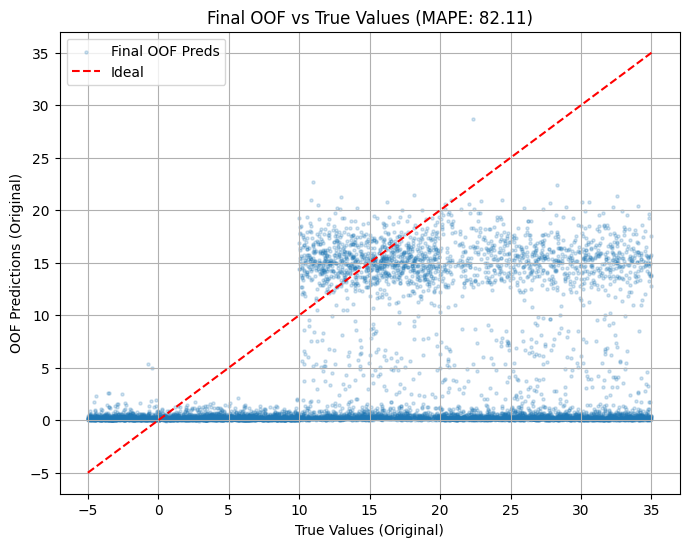


--- Feature Importance (dari Model Utama CatBoost) ---


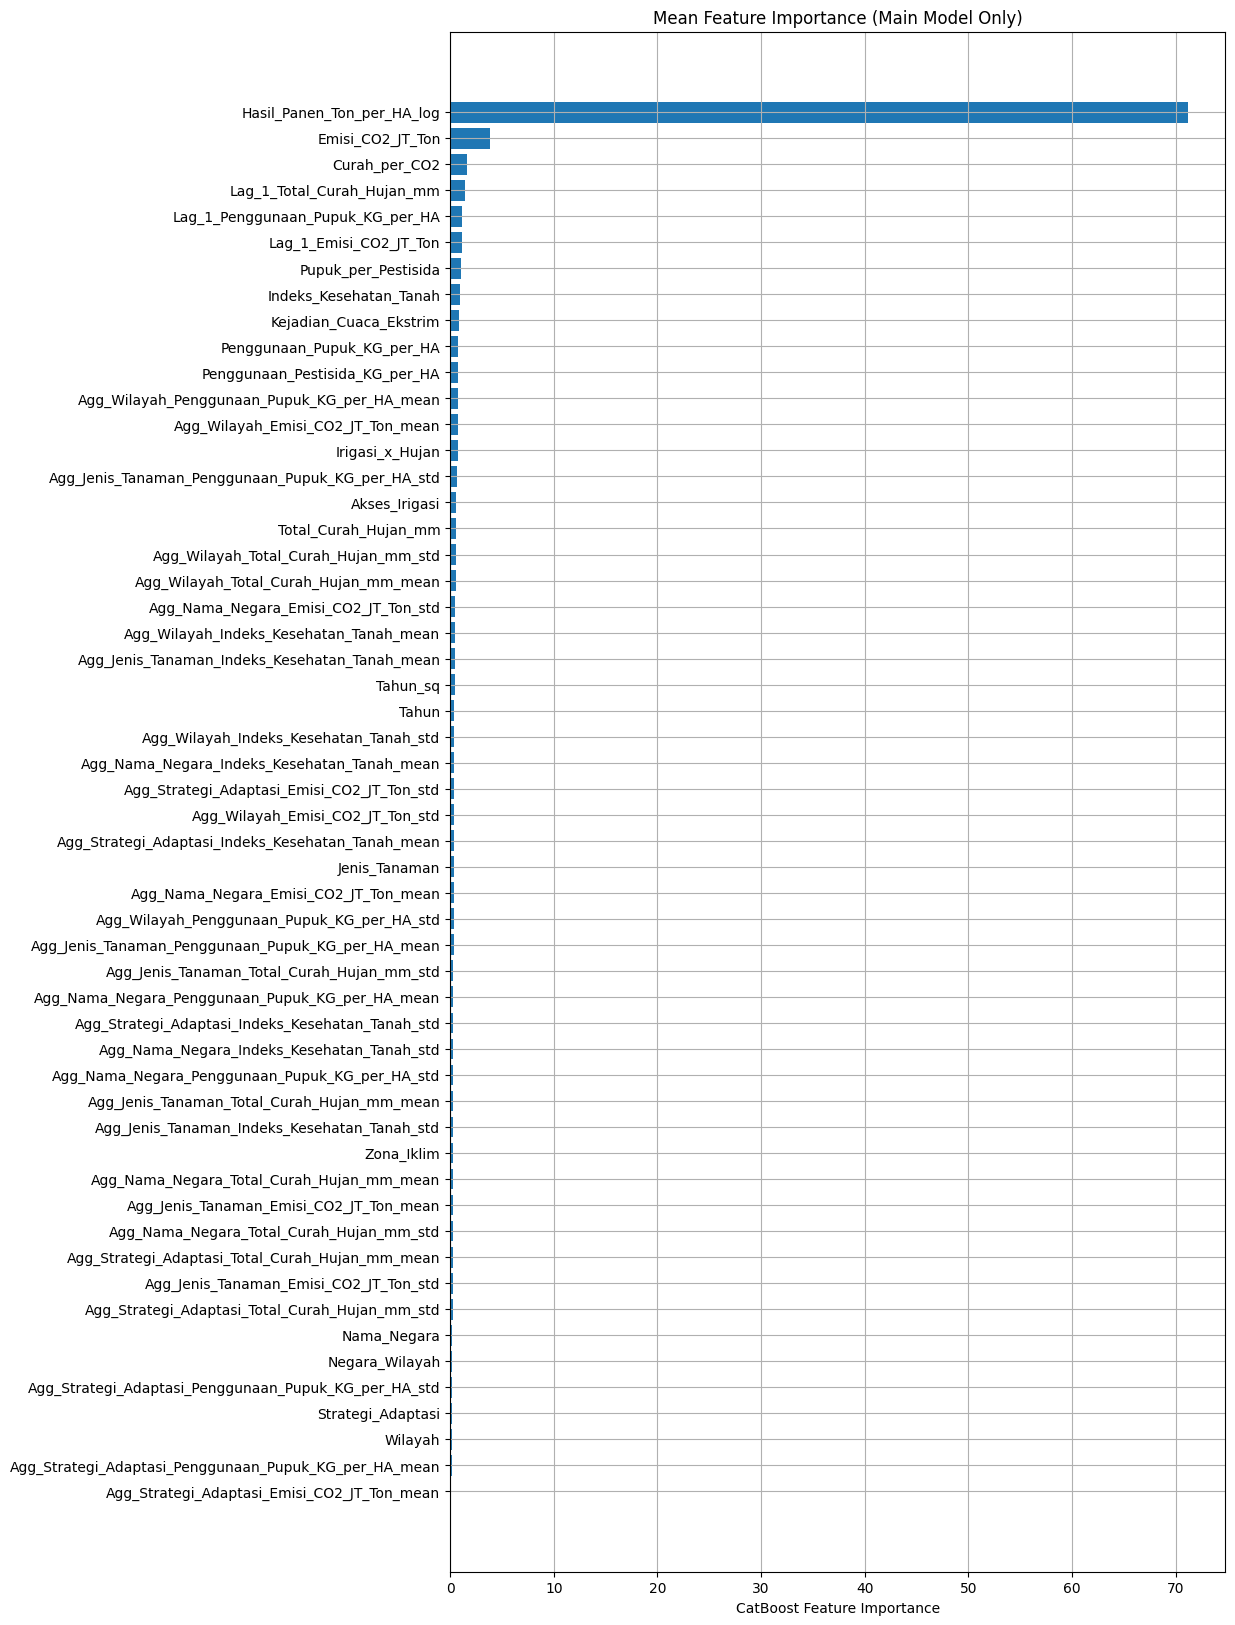

In [19]:
# ==============================
# Cell 12: OOF Score Final & Feature Importance
# ==============================
oof_score_final = mape_eps(y, oof_preds, eps=EPS)
print("\n" + "="*30)
print(f"Overall Final OOF Stabilized MAPE: {oof_score_final:.4f}")
print("="*30)

plt.figure(figsize=(8, 6))
plt.scatter(y, oof_preds, alpha=0.2, s=5, label='Final OOF Preds')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label="Ideal")
plt.xlabel("True Values (Original)"); plt.ylabel("OOF Predictions (Original)")
plt.title(f"Final OOF vs True Values (MAPE: {oof_score_final:.2f})")
plt.legend(); plt.grid(True); plt.show()

print("\n--- Feature Importance (dari Model Utama CatBoost) ---")
fi_df = pd.DataFrame({'feature': FEATURES})
importances = np.mean([m.get_feature_importance() for m in models_main], axis=0)
fi_df['importance'] = importances

plt.figure(figsize=(10, max(20, len(FEATURES)//3)))
fi_df_sorted = fi_df.sort_values(by="importance", ascending=True)
plt.barh(fi_df_sorted["feature"], fi_df_sorted["importance"])
plt.xlabel("CatBoost Feature Importance")
plt.title("Mean Feature Importance (Main Model Only)")
plt.grid(True); plt.show()

In [ ]:
# ==============================
# Cell 13: Submission 
# ==============================
# Kembalikan prediksi test ke skala semula
test_preds_final = inverse_signed_log1p(test_preds_final_transformed)

# Post-processing: Clip prediksi yang sangat dekat dengan nol
clip_threshold = 0.5 
print(f"\nMenerapkan clipping pada prediksi test dengan threshold = {clip_threshold}")
test_preds_final[np.abs(test_preds_final) < clip_threshold] = 0

print(f"Panjang sub: {len(sub)}, Panjang test_preds_final: {len(test_preds_final)}")

if len(sub) == len(test_preds_final):
    sub[TARGET] = test_preds_final
    sub.to_csv("submission_final_regularized.csv", index=False)
    print("Submission file (submission_final_regularized.csv) created.")
    display(sub.head())
else:
    print(f"ERROR: Panjang prediksi test ({len(test_preds_final)}) tidak cocok!")


Menerapkan clipping pada prediksi test dengan threshold = 0.5
Panjang sub: 2000, Panjang test_preds_final: 2000
Submission file (submission_final_regularized.csv) created.


,ID,Suhu_Rata_Rata_C
0,8000,0.000000
1,8001,17.251553
2,8002,0.000000
3,8003,15.509578
4,8004,0.000000
